# Лабораторная работа №2. Рекомендательные системы

Датасет: MTS Kion (онлайн-кинотеатр МТС), соревнование ODS.ai [competition-recsys-21](https://ods.ai/competitions/competition-recsys-21)

In [1]:
import glob
from collections import Counter
from itertools import combinations
from types import SimpleNamespace

import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.sparse.linalg import svds
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 60)

## 1. Датасет

Просмотры пользователей Kion за 13.03–22.08.2021: `interactions` — кто, что, когда и сколько смотрел, `users` — анкета (возраст, доход, пол, дети), `items` — фильмы и сериалы (тип, год, жанры и т.д.). Оценок нет, есть только факт и длительность просмотра — неявный фидбек. Подходит для рекомендаций: реальная история просмотров с датами плюс признаки пользователей и фильмов.

In [2]:
interactions = pd.concat([pd.read_csv(f, parse_dates=["last_watch_dt"])
                          for f in sorted(glob.glob("data/interactions_part*.csv.gz"))], ignore_index=True)
users = pd.read_csv("data/users.csv.gz")
items = pd.read_csv("data/items.csv.gz")

print("interactions:", interactions.shape)
print("users:", users.shape)
print("items:", items.shape)
print("Период:", interactions["last_watch_dt"].min().date(), "—", interactions["last_watch_dt"].max().date())
interactions.head()

interactions: (5476251, 5)
users: (840197, 5)
items: (15963, 14)
Период: 2021-03-13 — 2021-08-22


,user_id,item_id,last_watch_dt,total_dur,watched_pct
0,176549,9506,2021-05-11,4250,72.0
1,699317,1659,2021-05-29,8317,100.0
2,656683,7107,2021-05-09,10,0.0
3,864613,7638,2021-07-05,14483,100.0
4,964868,9506,2021-04-30,6725,100.0


In [3]:
users.head()

,user_id,age,income,sex,kids_flg
0,973171,age_25_34,income_60_90,М,1
1,962099,age_18_24,income_20_40,М,0
2,1047345,age_45_54,income_40_60,Ж,0
3,721985,age_45_54,income_20_40,Ж,0
4,704055,age_35_44,income_60_90,Ж,0


In [4]:
items[["item_id", "content_type", "title", "release_year", "genres", "countries", "age_rating"]].head()

,item_id,content_type,title,release_year,genres,countries,age_rating
0,10711,film,Поговори с ней,2002.0,"драмы, зарубежные, детективы, мелодрамы",Испания,16.0
1,2508,film,Голые перцы,2014.0,"зарубежные, приключения, комедии",США,16.0
2,10716,film,Тактическая сила,2011.0,"криминал, зарубежные, триллеры, боевики, комедии",Канада,16.0
3,7868,film,45 лет,2015.0,"драмы, зарубежные, мелодрамы",Великобритания,16.0
4,16268,film,Все решает мгновение,1978.0,"драмы, спорт, советские, мелодрамы",СССР,12.0


## 2. Разведочный анализ

In [5]:
print("Просмотров:", len(interactions))
print("Пользователей:", interactions["user_id"].nunique(), "; items:", interactions["item_id"].nunique())
print("Разреженность матрицы user × item:",
      round((1 - len(interactions) / (interactions["user_id"].nunique() * interactions["item_id"].nunique())) * 100, 3), "%")
interactions[["total_dur", "watched_pct"]].describe().round(1)

Просмотров: 5476251
Пользователей: 962179 ; items: 15706
Разреженность матрицы user × item: 99.964 %


,total_dur,watched_pct
count,5476251.0,5475423.0
mean,8295.5,46.4
std,48568.0,41.9
min,1.0,0.0
25%,371.0,4.0
50%,2898.0,32.0
75%,7116.0,100.0
max,80411672.0,100.0


Матрица пользователь × item заполнена на 0.04%. У `total_dur` длинный хвост: медиана 48 минут, среднее 2.3 часа.

In [6]:
tables = {"interactions": interactions, "users": users, "items": items}
for name, df in tables.items():
    print(name, "— полных дублей:", df.duplicated().sum())
print("Дублей пар (user_id, item_id):", interactions.duplicated(["user_id", "item_id"]).sum())

missing = pd.concat({name: df.isna().mean().mul(100).round(2) for name, df in tables.items()})
print("\nПропуски, % (только столбцы, где они есть):")
missing[missing > 0]

interactions — полных дублей: 0
users — полных дублей: 0
items — полных дублей: 0
Дублей пар (user_id, item_id): 0

Пропуски, % (только столбцы, где они есть):


interactions  watched_pct      0.02
users         age              1.68
              income           1.76
              sex              1.65
items         title_orig      29.72
              release_year     0.61
              countries        0.23
              for_kids        96.45
              age_rating       0.01
              studios         93.33
              directors        9.45
              actors          16.41
              description      0.01
              keywords         2.65
dtype: float64

In [7]:
user_ids = interactions["user_id"].unique()
item_ids = interactions["item_id"].unique()
print("Пользователей, которых нет в users:", round((~np.isin(user_ids, users["user_id"])).mean() * 100, 1), "%")
print("Items, которых нет в items:", (~np.isin(item_ids, items["item_id"])).sum())

Пользователей, которых нет в users: 22.6 %
Items, которых нет в items: 0


Дублей нет. Пропуски только в анкете (~1.7%) и редких полях каталога, жанры заполнены у всех — по ним считаю разнообразие. 23% пользователей нет в `users`, поэтому демографию не использую.

Граница выбросов по IQR: 17234 сек = 4.8 ч
Выше границы: 9.0 % строк
Меньше 1 минуты: 12.0 % строк


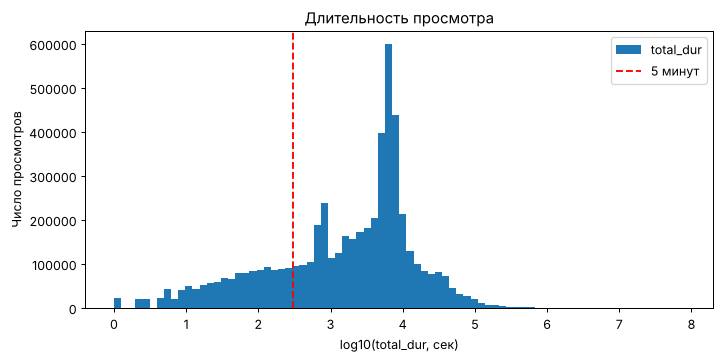

In [8]:
q1, q3 = interactions["total_dur"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print("Граница выбросов по IQR:", round(upper), "сек =", round(upper / 3600, 1), "ч")
print("Выше границы:", round((interactions["total_dur"] > upper).mean() * 100, 1), "% строк")
print("Меньше 1 минуты:", round((interactions["total_dur"] < 60).mean() * 100, 1), "% строк")

np.log10(interactions["total_dur"]).plot(kind="hist", bins=80, figsize=(9, 4))
plt.axvline(np.log10(300), color="red", linestyle="--", label="5 минут")
plt.title("Длительность просмотра")
plt.xlabel("log10(total_dur, сек)")
plt.ylabel("Число просмотров")
plt.legend()
plt.show()

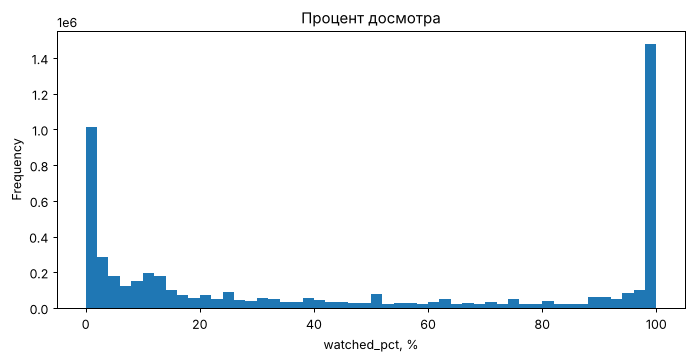

In [9]:
interactions["watched_pct"].plot(kind="hist", bins=50, figsize=(9, 4))
plt.title("Процент досмотра")
plt.xlabel("watched_pct, %")
plt.show()

По IQR 9% строк — выбросы (дольше 4.8 ч), но это долгие просмотры сериалов, а не ошибки, поэтому не удаляю. Слева горб коротких случайных запусков. У досмотра два пика: 0% (бросили) и 100% (досмотрели).

**Что рекомендуем:** фильм или сериал (`item_id`) — 10 штук, которые пользователь ещё не смотрел и, скорее всего, посмотрит в следующую неделю.

**Целевая переменная:** 1, если пользователь смотрел item не меньше 5 минут. Порог отрезает горб случайных запусков. Больше предобработки не нужно: дублей нет, а выбросы и пропуски на такой таргет не влияют.

In [10]:
pos = interactions[interactions["total_dur"] >= 300]
print("Положительных просмотров:", len(pos), f"({len(pos) / len(interactions):.0%})")
print("Пользователей:", pos["user_id"].nunique(), "; items:", pos["item_id"].nunique())

Положительных просмотров: 4196975 (77%)
Пользователей: 809577 ; items: 14163


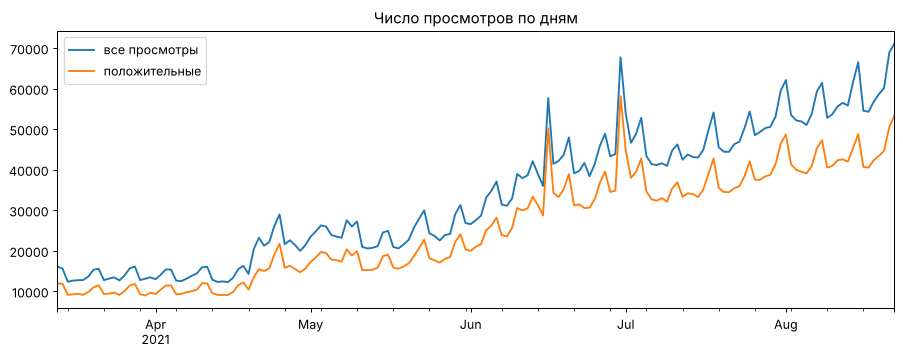

Самые частые items в дни пиков:
last_watch_dt
2021-06-16        Хрустальный
2021-06-30    Клиника счастья
Name: item_id, dtype: str


In [11]:
plt.figure(figsize=(12, 4))
interactions.groupby("last_watch_dt").size().plot(label="все просмотры")
pos.groupby("last_watch_dt").size().plot(label="положительные")
plt.title("Число просмотров по дням")
plt.xlabel("")
plt.legend()
plt.show()

top_day = pos[pos["last_watch_dt"].isin(pd.to_datetime(["2021-06-16", "2021-06-30"]))]
print("Самые частые items в дни пиков:")
print(top_day.groupby("last_watch_dt")["item_id"].agg(lambda s: s.value_counts().index[0]).map(items.set_index("item_id")["title"]))

Просмотров со временем всё больше, пики 16.06 и 30.06 — премьеры «Хрустальный» и «Клиника счастья». Поэтому train и test делю по времени.

Просмотров у пользователя: медиана 2.0 ; среднее 5.2 ; максимум 461
Пользователей с 1 просмотром: 38% ; с 10 и больше: 13%
Топ-1% items собирают 46% просмотров


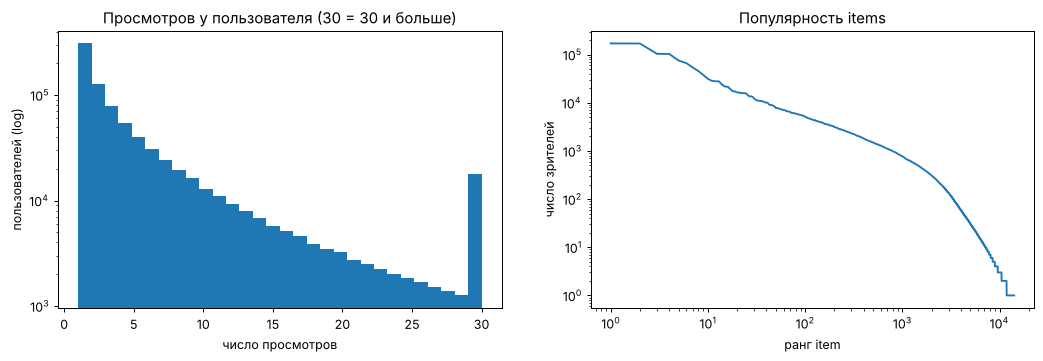

In [12]:
user_views = pos.groupby("user_id").size()
item_views = pos.groupby("item_id").size().sort_values(ascending=False)
print("Просмотров у пользователя: медиана", user_views.median(), "; среднее", round(user_views.mean(), 1), "; максимум", user_views.max())
print("Пользователей с 1 просмотром:", f"{(user_views == 1).mean():.0%}", "; с 10 и больше:", f"{(user_views >= 10).mean():.0%}")
print("Топ-1% items собирают", f"{item_views.head(len(item_views) // 100).sum() / item_views.sum():.0%}", "просмотров")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
user_views.clip(upper=30).plot(kind="hist", bins=30, logy=True, ax=axes[0])
axes[0].set_title("Просмотров у пользователя (30 = 30 и больше)")
axes[0].set_xlabel("число просмотров")
axes[0].set_ylabel("пользователей (log)")
axes[1].loglog(np.arange(1, len(item_views) + 1), item_views.values)
axes[1].set_title("Популярность items")
axes[1].set_xlabel("ранг item")
axes[1].set_ylabel("число зрителей")
plt.show()

In [13]:
item_views.head(10).rename("зрителей").to_frame().join(items.set_index("item_id")[["title", "content_type", "release_year"]])

,зрителей,title,content_type,release_year
item_id,,,,
10440,170897,Хрустальный,series,2021.0
15297,169968,Клиника счастья,series,2021.0
13865,103554,Девятаев,film,2021.0
9728,103284,Гнев человеческий,film,2021.0
4151,75285,Секреты семейной жизни,series,2021.0
3734,66543,Прабабушка легкого поведения,film,2021.0
2657,53899,Подслушано,series,2021.0
4880,45382,Афера,series,2021.0
142,37389,Маша,film,2020.0


У медианного пользователя 2 просмотра, у 38% — один. Топ-1% items собирает 46% просмотров, в топ-10 только новинки — популярность будет сильным бейзлайном.

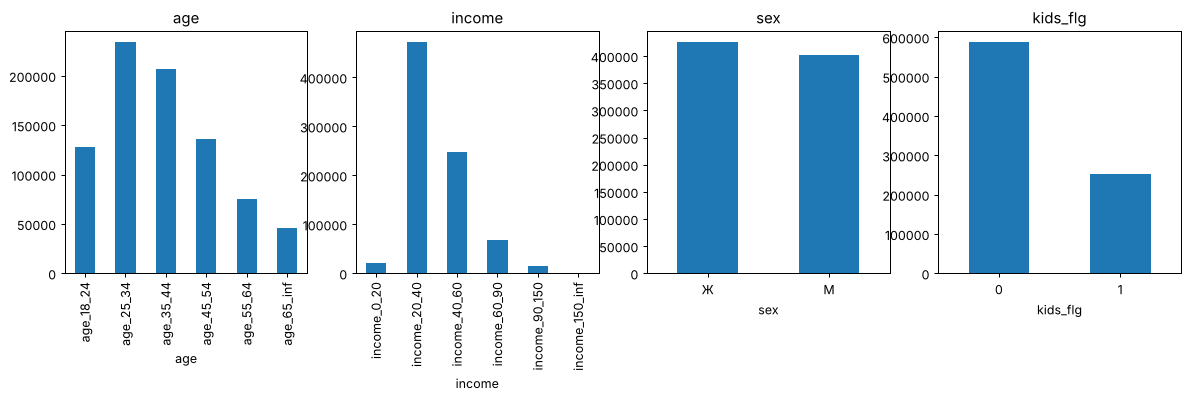

age
age_18_24     4.49
age_25_34     5.50
age_35_44     5.99
age_45_54     5.66
age_55_64     5.01
age_65_inf    4.35
нет данных    4.51
Name: просмотров, dtype: float64

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
income_order = ["income_0_20", "income_20_40", "income_40_60", "income_60_90", "income_90_150", "income_150_inf"]
users["age"].value_counts().sort_index().plot(kind="bar", ax=axes[0], title="age")
users["income"].value_counts().reindex(income_order).plot(kind="bar", ax=axes[1], title="income")
users["sex"].value_counts().plot(kind="bar", ax=axes[2], title="sex", rot=0)
users["kids_flg"].value_counts().plot(kind="bar", ax=axes[3], title="kids_flg", rot=0)
plt.show()

user_views.rename("просмотров").to_frame().join(users.set_index("user_id")["age"]).fillna({"age": "нет данных"}) \
    .groupby("age")["просмотров"].mean().round(2)

content_type
film      0.75
series    0.25
Name: proportion, dtype: float64


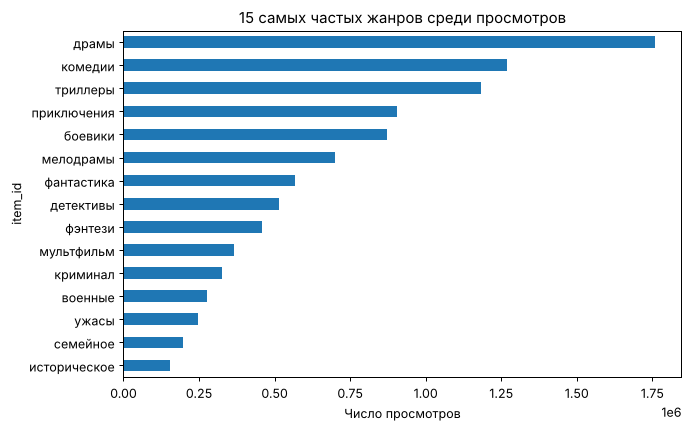

In [15]:
print(items["content_type"].value_counts(normalize=True).round(2))
genres = items.set_index("item_id")["genres"].str.lower().str.split(", ")
pos["item_id"].map(genres).explode().value_counts().head(15).sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("15 самых частых жанров среди просмотров")
plt.xlabel("Число просмотров")
plt.show()

Пользователи в основном 25–44 лет, число просмотров от возраста почти не зависит. Фильмов 75%, сериалов 25%, чаще всего смотрят драмы, комедии и триллеры.

Вывод: данные чистые, истории короткие, спрос сосредоточен на нескольких новинках и меняется во времени.

## 3. Методы

Четыре метода из разных семейств. ItemKNN, а не UserKNN: у большинства пользователей 1–2 просмотра, похожих пользователей не найти, а у items тысячи зрителей. `recommend` берёт 10 items с наибольшей оценкой, кроме уже просмотренных.

In [ ]:
def recommend(score, d, k=10, batch=5000):
    tie_break = (1e-6 * d.pop / d.pop.max()).astype(np.float32)
    recs = []
    for start in range(0, len(d.eval_rows), batch):
        rows = d.eval_rows[start:start + batch]
        scores = score(rows) + tie_break
        scores[d.X[rows].nonzero()] = -np.inf
        top = np.argpartition(-scores, k, axis=1)[:, :k]
        order = np.argsort(-np.take_along_axis(scores, top, axis=1), axis=1)
        recs.append(np.take_along_axis(top, order, axis=1))
    return d.item_ids[np.vstack(recs)]

**MostPop** — сколько пользователей посмотрели item за последние 7 дней train. Всем один и тот же список.

In [17]:
def fit_most_pop(d, days=7):
    recent = d.train
    if days:
        recent = recent[recent["last_watch_dt"] > recent["last_watch_dt"].max() - pd.Timedelta(days=days)]
    counts = recent["item_id"].value_counts().reindex(d.item_ids, fill_value=0).values.astype(np.float32)
    return lambda rows: np.tile(counts, (len(rows), 1))

**ItemKNN** — сходство items: косинус между множествами зрителей, sim(i, j) = общие зрители / (√n_i · √n_j + 10). Оценка item — сумма сходств с просмотренными, у каждого item 300 соседей.

In [ ]:
def fit_item_knn(d, k=300, shrink=10):
    X = d.X.tocsc()
    n = X.shape[1]
    norms = np.sqrt(d.pop)
    rows, cols, vals = [], [], []
    for s in range(0, n, 2000):
        e = min(s + 2000, n)
        sim = (X[:, s:e].T @ X).toarray() / (norms[s:e, None] * norms[None, :] + shrink)
        sim[np.arange(e - s), np.arange(s, e)] = 0
        nb = np.argpartition(-sim, k, axis=1)[:, :k]
        rows.append(np.repeat(np.arange(s, e), k))
        cols.append(nb.ravel())
        vals.append(np.take_along_axis(sim, nb, axis=1).ravel())
    S = sp.csr_matrix((np.concatenate(vals), (np.concatenate(rows), np.concatenate(cols))), shape=(n, n))
    return lambda rows: (d.X[rows] @ S).toarray()

**EASE** (семейство SLIM) — веса B между items: min ‖X − XB‖² + λ‖B‖², diag(B) = 0. Решение формулой: P = (XᵀX + λI)⁻¹, B_ij = −P_ij / P_jj. Беру 6000 самых популярных items (99% просмотров).

In [ ]:
def fit_ease(d, lam=1000, n_items=6000):
    top = np.sort(np.argsort(-d.pop)[:n_items])
    Xt = d.X[:, top]
    G = (Xt.T @ Xt).toarray().astype(np.float64)
    G[np.diag_indices(n_items)] += lam
    P = np.linalg.inv(G)
    B = (P / -np.diag(P)).astype(np.float32)
    B[np.diag_indices(n_items)] = 0

    def score(rows):
        s = np.full((len(rows), d.X.shape[1]), -1e9, dtype=np.float32)
        s[:, top] = Xt[rows] @ B
        return s
    return score

**PureSVD** — X ≈ UΣVᵀ, оценки x·V·Vᵀ (32 скрытых фактора). Столбцы X делю на (число зрителей)^0.4, иначе первые факторы описывают только популярность.

In [20]:
def fit_svd(d, k=32, beta=0.4):
    weights = sp.diags(np.maximum(d.pop, 1) ** -beta)
    _, _, vt = svds((d.X @ weights).astype(np.float32), k=k, random_state=0)
    V = vt.T
    return lambda rows: (d.X[rows] @ V) @ V.T

## 4. Метрики

- Precision@10 — доля угаданных среди 10 рекомендаций;
- Recall@10 — доля угаданных среди просмотренных в test;
- MAP@10 — среднее Precision@k по местам попаданий (метрика соревнования, ранжирование);
- NDCG@10 — попадание на месте k весит 1/log2(k+1), нормировано на идеальный список (ранжирование);
- Coverage@10 — доля каталога, попавшая в рекомендации;
- Novelty@10 — среднее −log2(доля зрителей item): чем реже item, тем выше;
- ILD@10 — разнообразие: среднее расстояние Жаккара между жанрами в списке.

In [21]:
genre_sets = {i: set(g) for i, g in genres.items()}


def average_precision(hits, n_relevant):
    precision_at_k = np.cumsum(hits) / np.arange(1, len(hits) + 1)
    return (precision_at_k * hits).sum() / n_relevant


def ndcg(hits, n_relevant):
    discounts = 1 / np.log2(np.arange(2, len(hits) + 2))
    return (hits * discounts).sum() / discounts[:min(n_relevant, len(hits))].sum()


def ild(rec):
    pairs = combinations([genre_sets[i] for i in rec], 2)
    return np.mean([1 - len(a & b) / len(a | b) for a, b in pairs])


def user_metrics(recs, d):
    pop = pd.Series(d.pop, index=d.item_ids)
    rows = []
    for rec, truth in zip(recs, d.truth):
        hits = np.array([i in truth for i in rec], dtype=float)
        rows.append({"Precision@10": hits.mean(), "Recall@10": hits.sum() / len(truth),
                     "MAP@10": average_precision(hits, len(truth)), "NDCG@10": ndcg(hits, len(truth)),
                     "ILD@10": ild(rec)})
    m = pd.DataFrame(rows)
    m["Novelty@10"] = -np.log2(pop[recs.ravel()].values.reshape(recs.shape) / d.X.shape[0]).mean(axis=1)
    return m


def evaluate(recs, d):
    result = user_metrics(recs, d).mean()
    result["Coverage@10"] = len(np.unique(recs)) / len(d.item_ids)
    return result


# проверка на примере: у пользователя 2 просмотра в test, мы попали на 1-м и 3-м месте
print("AP =", round(average_precision(np.array([1, 0, 1]), 2), 3), "(должно быть (1/1 + 2/3) / 2 = 0.833)")
print("NDCG =", round(ndcg(np.array([1, 0, 1]), 2), 3), "(должно быть (1 + 1/2) / (1 + 1/log2(3)) = 0.920)")

AP = 0.833 (должно быть (1/1 + 2/3) / 2 = 0.833)
NDCG = 0.92 (должно быть (1 + 1/2) / (1 + 1/log2(3)) = 0.920)


## 5. Обучающая и тестовая выборки

Test — последняя неделя (16–22.08), train — всё, что раньше. Оцениваю пользователей, которые есть и в train, и в test; уже просмотренное не рекомендую.

In [22]:
test_start = pos["last_watch_dt"].max() - pd.Timedelta(days=6)
train = pos[pos["last_watch_dt"] < test_start]
test = pos[pos["last_watch_dt"] >= test_start]
warm = test["user_id"].isin(train["user_id"])

print("train:", train["last_watch_dt"].min().date(), "—", train["last_watch_dt"].max().date(), ";", len(train), "просмотров")
print("test: ", test["last_watch_dt"].min().date(), "—", test["last_watch_dt"].max().date(), ";", len(test), "просмотров")
print("Пользователей в test:", test["user_id"].nunique(), "; из них есть в train:", test.loc[warm, "user_id"].nunique())
print("Просмотров в test items, которых не было в train:", f"{(~test['item_id'].isin(train['item_id'])).mean():.1%}")

train: 2021-03-13 — 2021-08-15 ; 3881529 просмотров
test:  2021-08-16 — 2021-08-22 ; 315446 просмотров
Пользователей в test: 138232 ; из них есть в train: 92532
Просмотров в test items, которых не было в train: 2.2%


In [ ]:
def prepare(train, test, n_users=None):
    d = SimpleNamespace(train=train)
    d.user_ids = np.sort(train["user_id"].unique())
    d.item_ids = np.sort(train["item_id"].unique())
    user_index = pd.Series(np.arange(len(d.user_ids)), index=d.user_ids)
    item_index = pd.Series(np.arange(len(d.item_ids)), index=d.item_ids)
    d.X = sp.csr_matrix((np.ones(len(train), dtype=np.float32),
                         (user_index[train["user_id"]].values, item_index[train["item_id"]].values)),
                        shape=(len(d.user_ids), len(d.item_ids)))
    d.pop = np.asarray(d.X.sum(axis=0)).ravel()
    truth = test[test["user_id"].isin(d.user_ids)].groupby("user_id")["item_id"].apply(set)
    if n_users:
        truth = truth.sample(n_users, random_state=42)
    d.eval_rows = user_index[truth.index].values
    d.truth = list(truth)
    return d


d = prepare(train, test)
print("Матрица X:", d.X.shape, "; оцениваем пользователей:", len(d.eval_rows))

Матрица X: (763877, 14034) ; оцениваем пользователей: 92532


Параметры подбираю на неделе перед тестом (09–15.08, 20 000 пользователей), чтобы не подгонять под тест.

In [24]:
val_start = test_start - pd.Timedelta(days=7)
d_val = prepare(train[train["last_watch_dt"] < val_start], train[train["last_watch_dt"] >= val_start], n_users=20000)

candidates = {
    "MostPop, весь период": lambda d: fit_most_pop(d, days=None),
    "MostPop, 30 дней": lambda d: fit_most_pop(d, days=30),
    "MostPop, 7 дней": lambda d: fit_most_pop(d, days=7),
    "ItemKNN, k=30": lambda d: fit_item_knn(d, k=30),
    "ItemKNN, k=300": lambda d: fit_item_knn(d, k=300),
    "EASE, λ=100": lambda d: fit_ease(d, lam=100),
    "EASE, λ=1000": lambda d: fit_ease(d, lam=1000),
    "EASE, λ=5000": lambda d: fit_ease(d, lam=5000),
    "PureSVD, k=32, β=0": lambda d: fit_svd(d, k=32, beta=0),
    "PureSVD, k=128, β=0": lambda d: fit_svd(d, k=128, beta=0),
    "PureSVD, k=32, β=0.4": lambda d: fit_svd(d, k=32, beta=0.4),
    "PureSVD, k=128, β=0.4": lambda d: fit_svd(d, k=128, beta=0.4),
}
validation = pd.DataFrame({name: evaluate(recommend(fit(d_val), d_val), d_val) for name, fit in candidates.items()}).T
validation[["MAP@10", "NDCG@10", "Coverage@10"]].round(4)

,MAP@10,NDCG@10,Coverage@10
"MostPop, весь период",0.0833,0.1167,0.0022
"MostPop, 30 дней",0.0889,0.1261,0.0020
"MostPop, 7 дней",0.0901,0.1302,0.0020
"ItemKNN, k=30",0.0883,0.1270,0.3179
"ItemKNN, k=300",0.0890,0.1284,0.3064
"EASE, λ=100",0.0957,0.1363,0.1773
"EASE, λ=1000",0.0961,0.1367,0.1412
"EASE, λ=5000",0.0956,0.1357,0.1186
"PureSVD, k=32, β=0",0.0273,0.0436,0.0187
"PureSVD, k=128, β=0",0.0183,0.0297,0.0497


Выбрал MostPop за 7 дней, ItemKNN k=300, EASE λ=1000, PureSVD k=32, β=0.4. Без поправки на популярность (β=0) PureSVD в 3 раза хуже.

Результаты на тестовой неделе:

In [25]:
models = {
    "MostPop": fit_most_pop(d, days=7),
    "ItemKNN": fit_item_knn(d, k=300),
    "EASE": fit_ease(d, lam=1000),
    "PureSVD": fit_svd(d, k=32, beta=0.4),
}
recs = {name: recommend(score, d) for name, score in models.items()}
per_user = {name: user_metrics(r, d) for name, r in recs.items()}
results = pd.DataFrame({name: evaluate(r, d) for name, r in recs.items()}).T
results = results[["Precision@10", "Recall@10", "MAP@10", "NDCG@10", "Coverage@10", "Novelty@10", "ILD@10"]]
results.round(4)

,Precision@10,Recall@10,MAP@10,NDCG@10,Coverage@10,Novelty@10,ILD@10
MostPop,0.0360,0.1993,0.0861,0.1264,0.0021,4.7008,0.8883
ItemKNN,0.0366,0.1870,0.0865,0.1249,0.5343,5.5368,0.7386
EASE,0.0383,0.1961,0.0922,0.1324,0.2038,5.4527,0.7709
PureSVD,0.0341,0.1774,0.0826,0.1186,0.0594,4.8905,0.7290


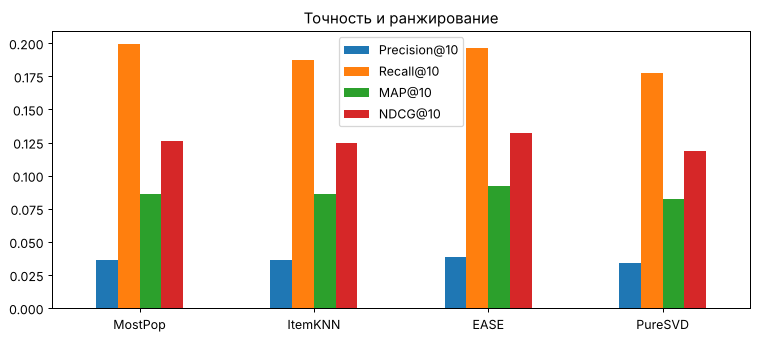

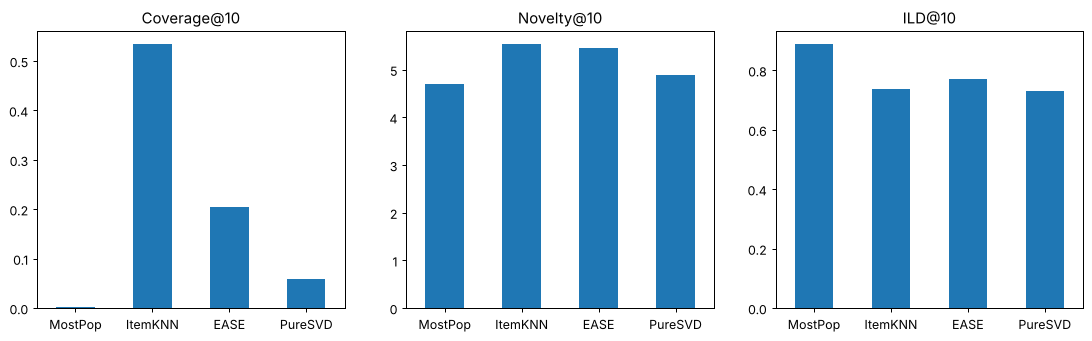

In [26]:
results[["Precision@10", "Recall@10", "MAP@10", "NDCG@10"]].plot(kind="bar", figsize=(10, 4), rot=0)
plt.title("Точность и ранжирование")
plt.show()

results[["Coverage@10", "Novelty@10", "ILD@10"]].plot(kind="bar", subplots=True, layout=(1, 3), figsize=(15, 4),
                                                      rot=0, legend=False, color="C0")
plt.show()

Пользователей в группах: {'1': 13487, '2–4': 24818, '5–9': 21418, '10+': 32809}


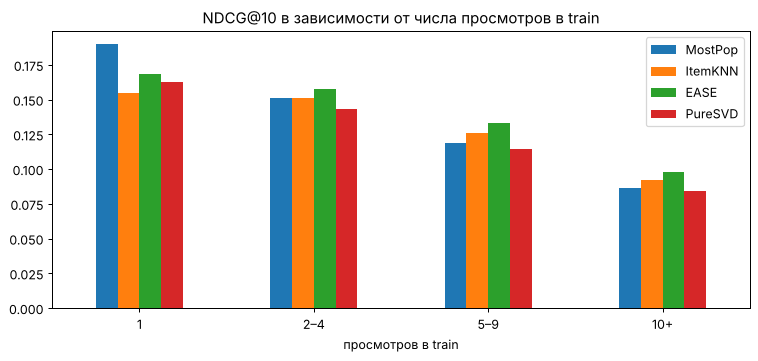

,MostPop,ItemKNN,EASE,PureSVD
1,0.1900,0.1547,0.1683,0.1627
2–4,0.1513,0.1511,0.1575,0.1432
5–9,0.1190,0.1263,0.1329,0.1147
10+,0.0863,0.0919,0.0982,0.0845


In [27]:
n_views = np.asarray(d.X[d.eval_rows].sum(axis=1)).ravel()
segment = pd.cut(n_views, [0, 1, 4, 9, np.inf], labels=["1", "2–4", "5–9", "10+"])
by_segment = pd.DataFrame({name: m["NDCG@10"].groupby(segment, observed=True).mean() for name, m in per_user.items()})
print("Пользователей в группах:", pd.Series(segment).value_counts().sort_index().to_dict())
by_segment.plot(kind="bar", figsize=(10, 4), rot=0)
plt.title("NDCG@10 в зависимости от числа просмотров в train")
plt.xlabel("просмотров в train")
plt.show()
by_segment.round(4)

In [ ]:
titles = items.set_index("item_id")["title"]
u = next(i for i in np.where(n_views == 5)[0] if set(recs["EASE"][i]) & d.truth[i])
uid = d.user_ids[d.eval_rows[u]]
print("Смотрел в train:", ", ".join(titles[train.loc[train["user_id"] == uid, "item_id"]]))
print("Посмотрел в test:", ", ".join(titles[list(d.truth[u])]))
pd.DataFrame({name: [("✔ " if i in d.truth[u] else "") + titles[i] for i in r[u]] for name, r in recs.items()},
             index=range(1, 11))

Смотрел в train: Человек-паук: Через вселенные, Звёздные войны: Атака клонов, Железный человек, Железный человек 2, Мстители: Война бесконечности
Посмотрел в test: Мстители


,MostPop,ItemKNN,EASE,PureSVD
1,Хрустальный,Железный человек 3,Железный человек 3,Мстители: Эра Альтрона
2,Клиника счастья,Мстители: Эра Альтрона,Мстители: Финал,✔ Мстители
3,Гнев человеческий,✔ Мстители,Звёздные войны: Скрытая угроза,Мстители: Финал
4,Девятаев,Мстители: Финал,✔ Мстители,Первый мститель: Противостояние
5,Прабабушка легкого поведения,Первый мститель: Противостояние,Звёздные войны: Месть ситхов,Тор: Рагнарёк
6,Секреты семейной жизни,Первый мститель: Другая война,Мстители: Эра Альтрона,Железный человек 3
7,Фемида видит,Первый мститель,Первый мститель,Первый мститель: Другая война
8,Радиовспышка,Тор: Рагнарёк,Тор,Первый мститель
9,Рядовой Чээрин,Звёздные войны: Месть ситхов,Первый мститель: Противостояние,Тор
10,Лето - это море,Тор,Звёздные войны: Эпизод 4 — Новая надежда,Тор: Царство тьмы


Лучший — EASE: MAP@10 = 0.092, NDCG@10 = 0.132, на 7% выше MostPop. MostPop почти не хуже, а по Recall даже лучше: истории короткие, а смотрят в основном премьеры. Для пользователей с 1 просмотром лучше всех MostPop, с 2 и больше — EASE.

ItemKNN покрывает 53% каталога и даёт самую высокую новизну, MostPop — 0.2% каталога. Разнообразие жанров выше у MostPop: персональные модели подстраиваются под любимые жанры. В примере фанату Marvel MostPop предлагает хиты недели, а персональные модели — Marvel, и все три угадывают «Мстителей».

## 6. Улучшения и выводы

- учитывать свежесть просмотров и смешивать со свежей популярностью;
- давать вес по проценту досмотра (iALS);
- двухэтапная схема: кандидаты от моделей + бустинг с признаками пользователей и фильмов;
- новым пользователям — популярное в их возрастной группе;
- модели по последовательности просмотров (SASRec).

Вывод: лучший метод — EASE, новым пользователям и пользователям с 1 просмотром — популярное за последнюю неделю.